In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [10]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [11]:
prefix = '/mnt/staging/' # or 
mouse='cm229'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'

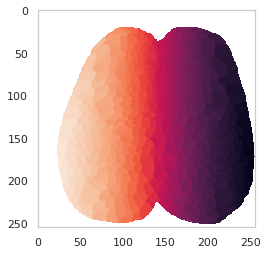

In [14]:
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse)
S1_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse)
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [16]:
# files awake:
f1 = list(set(glob.glob(step_2_root+"*229/[8]/*[E]*.mat")) )

file_spont = f1`
file_spont

['/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm229/8/H_runE_stim_1.mat']

In [17]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

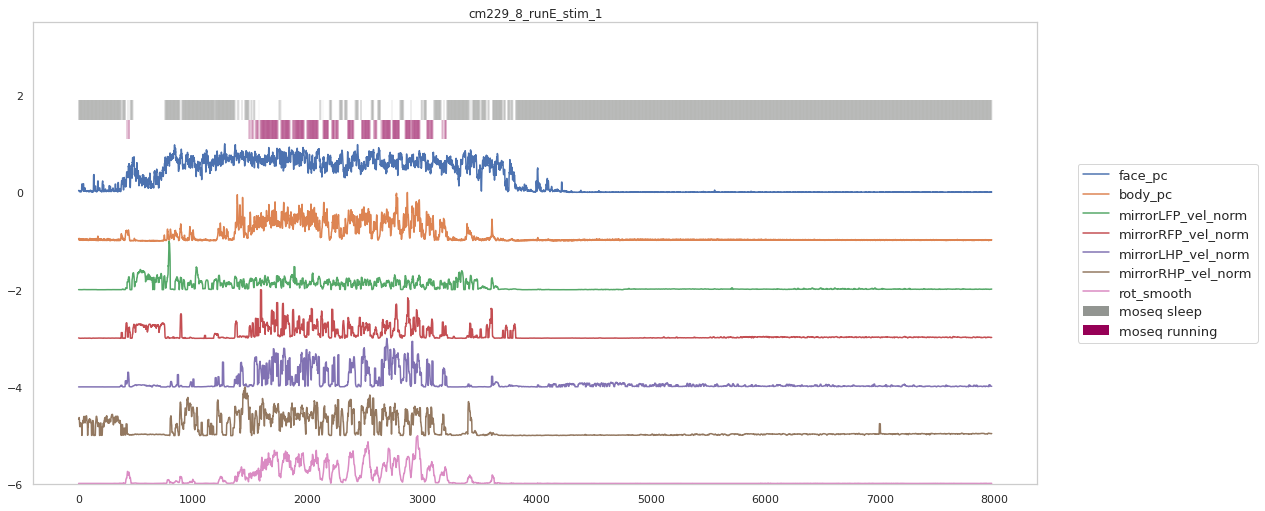

In [53]:
sns.set_style("whitegrid", {'axes.grid' : False})
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

data_joint=pd.DataFrame()
big_df_concat = pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    
    ################################### identity 
    run_name = fname[-15:-4]
    day = fname.split(mouse)[1][1:2]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]


        
    with(h5py.File(pjoin(step_3_root,
                             mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
        motionS = f_b['motionS']# this is the HDF5 reference
        motion_pc = {key: [] for key in list(motionS.keys())} 
        motion_pc_2detect = {key: [] for key in list(motionS.keys())} 
        for key in list(motionS.keys()):

            motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
            # (200,T)
            ss=motion_pc[key].shape
            tocut = ss[1]%4
            if tocut ==0:
                motion_pc[key] = np.mean(motion_pc[key].values.reshape((ss[0],int(ss[1]/4),4)),axis=2)
            else:
                motion_pc[key] = np.mean(motion_pc[key].iloc[:,:-tocut].values.reshape((ss[0],-1,4)),axis=2)

            motion_pc_2detect[key] = pd.DataFrame(motion_pc[key]).rolling(window=30,axis=1).std()                
            motion_pc[key] = pd.DataFrame(motion_pc[key]).rolling(window=5,axis=1).std()
            motion_pc_2detect[key]=motion_pc_2detect[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            motion_pc[key]=motion_pc[key].iloc[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = stats.zscore(np.array(face_pc))
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = stats.zscore(np.array(body_pc))
  



#     f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
#     Dataframe = pd.read_hdf(f_name_dlc)
#     scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
#     new_df = Dataframe[scorer] # de-level

#     paws_vel_df = pd.DataFrame()
#     bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

#     for i_bpt,bpt in enumerate(['LFP','RFP']):#make sure RFP comes out last
#         vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
#         vel_smooth = pd.DataFrame(vel).rolling(40).std()
#         vel = pd.DataFrame(vel).rolling(40).std()
#         tocut = vel.shape[0]%4
#         if tocut ==0:
#             vel = np.mean(vel.values.reshape((-1,4)),axis=1)
#             vel_smooth = np.mean(vel_smooth.values.reshape((-1,4)),axis=1)
#         else:
#             vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)  
#             vel_smooth = np.mean(vel_smooth[:-tocut].values.reshape((-1,4)),axis=1) 

#         paws_vel_df[bpt] = stats.zscore(vel[500:-505])
#         vel_ds = paws_vel_df[bpt].copy()
#         vel_ds[vel_ds>3]=np.nan;
#         paws_vel_df[bpt]=vel_ds
#         paws_vel_df[bpt] = paws_vel_df[bpt].fillna(0)
#         paws_vel_df[bpt]=np.array(paws_vel_df[bpt].interpolate())

#         vel_smooth = stats.zscore(vel_smooth[500:-505])
#         vel_smooth[vel_smooth>3]=np.nan;
#         vel_smooth=np.array(pd.DataFrame(vel_smooth).interpolate())


#     LFP_vel = stats.zscore(np.array(paws_vel_df['LFP']))
#     RFP_vel = stats.zscore(np.array(paws_vel_df['RFP']))
#     vel_smooth = stats.zscore(vel_smooth)

#     # is_groom plot # (480,360)
#     import matplotlib.patches as patches

#     x_top_left=80
#     x_botton_right=240
#     y_top_left=150
#     y_botton_right=450

#     out_h = int(x_botton_right - x_top_left)
#     out_w = int(y_botton_right - y_top_left)
#     y = x_top_left
#     x = y_top_left

#     fig,ax = plt.subplots(1)
#     plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
#     plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
#     rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
#     plt.ylim([0,360])
#     plt.xlim([0,480])
#     plt.legend()
#     ax.add_patch(rect)
#     plt.gca().invert_yaxis()      


#     is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
#     is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
#     is_groom = np.logical_and(is_groom_LFP,is_groom_RFP)
#     is_groom_smooth = is_groom.rolling(60).mean()
#     if tocut ==0:
#         is_groom_smooth_ds = np.mean(is_groom_smooth.values.reshape((-1,4)),axis=1)
#     else:
#         is_groom_smooth_ds = np.mean(is_groom_smooth[:-tocut].values.reshape((-1,4)),axis=1) #(11980,)
#     is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

#     if tocut ==0:
#         new_df = new_df.groupby(np.arange(new_df.shape[0])//4, axis=0).mean()
#     else:
#         new_df = new_df[:-tocut].groupby(np.arange(new_df[:-tocut].shape[0])//4, axis=0).mean()

#     new_df = new_df.iloc[500:-505]


#     except:
#         print('grooming missing ',mouse_day+'_'+run)   
#         continue
        
    f_name_dlc = glob.glob(mirror_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df_2 = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

    for i_bpt,bpt in enumerate(['LFP','RFP','LHP','RHP']):
        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df_2[bpt]['x'].values.flatten(), new_df_2[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel).rolling(40).std()
        tocut = vel.shape[0]%4
        if tocut ==0:
            vel = np.mean(vel.values.reshape((-1,4)),axis=1)
        else:
            vel = np.mean(vel[:-tocut].values.reshape((-1,4)),axis=1)   
        paws_vel_df[bpt] = vel[500:-505]

    mirrorLFP_vel = np.array(paws_vel_df['LFP'])
    mirrorRFP_vel = np.array(paws_vel_df['RFP'])
    mirrorLHP_vel = np.array(paws_vel_df['LHP'])
    mirrorRHP_vel = np.array(paws_vel_df['RHP'])

    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)

    with h5py.File(fname,'r') as f_H: 
        m=f_H['m']
        a=np.array(m['DAQ_ds'])
        rot = np.rad2deg(np.unwrap(a[:,-1]))
        rot = np.diff(rot)
        z = np.abs(stats.zscore(rot))
        threshold = 3
        outlier_ind = np.squeeze(np.where(z > 3))
        rot[outlier_ind]=np.nan
        rot_smooth = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).mean().fillna(0))))
        rot_smooth = rot_smooth[500:-504]


    
    big_df = pd.DataFrame()
    all_bev = ['face_pc','body_pc',
              # 'LFP_vel_norm','RFP_vel_norm',
               'mirrorLFP_vel_norm','mirrorRFP_vel_norm','mirrorLHP_vel_norm','mirrorRHP_vel_norm',
              'rot_smooth']
    for bev in all_bev:
        exec("big_df[bev] = normalize({})".format(bev))
    # big_df['rise_LFP']=rise_LFP
    # big_df['is_groom_smooth_ds']=is_groom_smooth_ds
    
    #behavior segmentation
#     is_whisking = np.logical_and(np.logical_and(big_df['whisk_vel_norm']>0.3, 
#                               big_df['LFP_vel_norm']<0.1),big_df['rot_raw']<0.2)
#     is_reach = big_df['rise_LFP']>22
    
#     is_running = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
#                               big_df['LFP_vel_norm']>0.1),big_df['rot_raw']>0.2),~is_reach)
    
#     is_groom_paw = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
#                               big_df['LFP_vel_norm']>0.1),big_df['rot_raw']<0.2),~is_reach)
#     is_groom_lick = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
#                               big_df['LFP_vel_norm']<0.1),big_df['rot_raw']<0.2),~is_reach)     
#     is_rest = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
#                               big_df['LFP_vel_norm']<0.1),big_df['rot_raw']<0.2),big_df['whisk_vel_norm']<0.1)
    
    is_sleep = np.logical_and(big_df['mirrorRFP_vel_norm']<0.1,big_df['rot_smooth']<0.2)
    is_running = np.logical_and(big_df['mirrorRFP_vel_norm']>0.1,big_df['rot_smooth']>0.2)

    moseq_list = ['is_sleep','is_running']
    for moseq in moseq_list:
        exec("big_df[moseq] = {}".format(moseq))
        
    tmp = pd.concat([big_df], keys=[mouse_day+'_'+run], names=['row_level'])
    big_df_concat = big_df_concat.append(tmp)

    
    
    plt.figure(figsize=(18,8.5))
    for i_bev,bev in enumerate(all_bev):
        plt.plot(big_df[bev]-i_bev,label=bev)
    
    col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
    col_list_palette = sns.xkcd_palette(col_list)
    
    # moseq
    for i, moseq in enumerate(moseq_list):
        plt.vlines(np.where(big_df[moseq]==True), 1.5-i*0.4, 1.9-i*0.4,linewidth=0.1,color=col_list_palette[i])
        plt.vlines(0, 8, 9,linewidth=10,color=col_list_palette[i],label='moseq '+moseq[3:])#for the legend

    plt.ylim([-6,3.5])
    plt.title(mouse_day+'_'+run_name)
    plt.legend(bbox_to_anchor=(1.04,0.5), loc="center left", borderaxespad=0,fontsize = 13)

    

In [54]:
save_root = str(PREPARES / "behavior-segment") + "/"
save_pickle(big_df_concat,save_root+'big_df_concat_dexmedetomidine_'+mouse)

In [34]:
big_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm125_4_runH 0      0.006169  0.038882        0.066531       0.000948   
             1      0.052608  0.039419        0.069216       0.001818   
             2      0.075854  0.041542        0.083590       0.002110   
             3      0.089070  0.041938        0.094808       0.002439   
             4      0.092121  0.040656        0.102516       0.002970   
...                      ...       ...             ...            ...   
cm125_2_runE 10970  0.014238  0.018276        0.029196       0.057351   
             10971  0.013492  0.019683        0.025570       0.057617   
             10972  0.013102  0.020391        0.014052       0.054439   
             10973  0.012617  0.021682        0.010461       0.053040   
             10974  0.005797  0.010315        0.009793       0.053639   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm125_4_runH 0           0.880382      0.001779      0.003284   
             1           0.891760      0.001700      0.003253   
             2           0.883535      0.001681      0.003860   
             3           0.891860      0.001636      0.004015   
             4           0.886659      0.001607      0.004075   
...                           ...           ...           ...   
cm125_2_runE 10970       0.352799      0.000884      0.004909   
             10971       0.341361      0.000978      0.004605   
             10972       0.352594      0.000934      0.004643   
             10973       0.339506      0.000919      0.004768   
             10974       0.337141      0.000922      0.004743   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm125_4_runH 0                0.001970            0.015436   
             1                0.001847            0.015213   
             2                0.001832            0.015173   
             3                0.001776            0.015634   
             4                0.001758            0.014857   
...                                ...                 ...   
cm125_2_runE 10970            0.003185            0.004022   
             10971            0.003210            0.004284   
             10972            0.003045            0.004366   
             10973            0.002882            0.004467   
             10974            0.002800            0.004486   

                    mirrorLHP_vel_norm  mirrorRHP_vel_norm   rot_raw  \
row_level                                                              
cm125_4_runH 0                0.001277            0.006035  0.003904   
             1                0.001306            0.005877  0.004106   
             2                0.001458            0.005893  0.004106   
             3                0.001448            0.005506  0.004106   
             4                0.001569            0.005365  0.004289   
...                                ...                 ...       ...   
cm125_2_runE 10970            0.001306            0.003181  0.026550   
             10971            0.001273            0.002984  0.026550   
             10972            0.001361            0.002873  0.026550   
             10973            0.001353            0.002476  0.026550   
             10974            0.001307            0.003006  0.025670   

                    rise_LFP  is_groom_smooth_ds  is_rest  is_whisking  \
row_level                                                                
cm125_4_runH 0      0.190715                 0.0     True        False   
             1      0.182574                 0.0     True        False   
             2      0.098532                 0.0     True        False   
             3      0.087058                 0.0     True        False   
             4      0.081799         

In [33]:
save_root = str(PREPARES / "behavior-segment") + "/"
save_pickle(big_df_concat,save_root+'big_df_concat_'+mouse)